In [1]:
import sys
# sys.path.insert(0, '../../Utilities/')

# from jax.example_libraries import optimizers
import jax.numpy as jnp
import numpy as np
from jax import grad, jit, vmap, value_and_grad, hessian
from jax import random
from functools import partial
import flax.linen as nn
import jax
import optax
import pickle
from datetime import datetime
import os
import numpy as np
from scipy import sparse
import time
from jax import grad, hessian, jit, vmap, pmap
from jax.tree_util import tree_leaves
from datetime import datetime
import matplotlib.pyplot as plt
import pickle
import flax.linen as nn
import optax
import optax.tree_utils as otu
from NN_class import MLP
from my_helpers import plot_u_theta, plot_kh, plot_loss_history
from functools import partial
from Pwp_class import PiecewiseLinearPolynomials
from minmax_opt_class import pytree_l2_norm, MinMaxOptProb
from seq_minmax_opt_class import SequentialMinMaxOptProb


import matplotlib.pyplot as plt
import scipy.io
from scipy.interpolate import griddata

import time
import matplotlib.gridspec as gridspec
from mpl_toolkits.axes_grid1 import make_axes_locatable
import mpmath

# Generate key which is used to generate random numbers
key = random.PRNGKey(1)

In [2]:
def u0(x):
    u = jnp.zeros_like(x)
    u = jnp.where((x > 0) & (x < 1), 1.0, u)
    return u

def u_exact(t, x):
    # Initialize u as zero
    u = 0.0
    # Condition 1: x < 0, u = 0 (already zero by default)
    # Condition 2: 0 < x < t and t > 0, u = x/t
    u = jnp.where((x > 0) & (x < t) & (t > 0), x / t, u)
    
    # Condition 3: t < x < 1 + t/2, u = 1
    u = jnp.where((x > t) & (x < 1 + t / 2), 1.0, u)
    
    # Condition 4: x > 1 + t/2, u = 0 (already zero by default)
    return u
vmap_u_exact = vmap(u_exact, in_axes=(0, 0), out_axes=0)

# Boundary at x=-1
def u1(x):
    return 0
vmap_u1 = vmap(u1, in_axes=0, out_axes=0)


# Boundary at x=2
def u2(x):
    return 0
vmap_u2 = vmap(u2, in_axes=0, out_axes=0)

def res_visc(u_quad, u_t, u_x, u_xx, nu):
    return u_t + u_quad * u_x - nu*u_xx
def res(u_quad, u_t, u_x):
    return u_t + u_quad * u_x


t_min = 0
t_max = 3
x_min = -1
x_max = 2
Nt = 101
Nx = 301
layers = [2, 50, 50, 50, 50, 50, 1]
hidden_dims = layers[1:-1]

# Domain bounds
lb = jnp.array([t_min, x_min])
ub = jnp.array([t_max, x_max])

In [3]:
seq_trainer = SequentialMinMaxOptProb(
    num_segments=3,
    total_t_min=t_min,
    total_t_max=t_max,
    N_t=16,
    N_x=48,
    lr_theta=0.0002,
    hidden_dims=hidden_dims,
    seed=0,
    N_bc=Nt,
    N_ic=Nx,
    x_min=x_min, x_max=x_max,
    u0=u0, u1=vmap_u1, u2=vmap_u2,
    nu=0.01,
    res_visc=res_visc,
    res=res,
)



Plotting before training segment 1/3 (t = [0.0000, 0.6667])


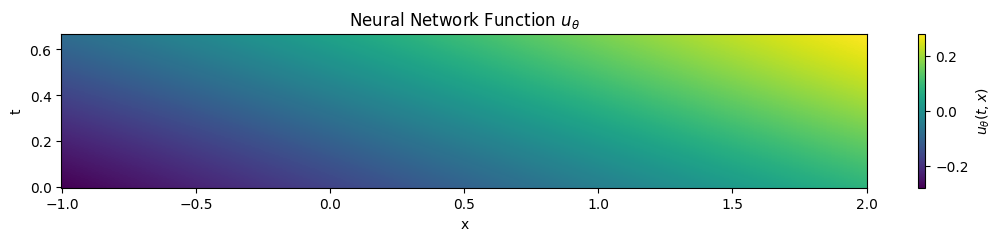


Pre-training segment 1/3 (t = [0.0000, 0.6667])

Starting Pre-Train Stage
Iteration 0, lambda_ic: 1.453648328781128, lambda_bc: 1.3487604856491089, lambda_r: 1.0676321983337402.
Pre-train Iteration 0, Loss_int: 0.19504640, Loss_ibc: 0.49710038
Pre-train Iteration 200, Loss_int: 0.00423437, Loss_ibc: 0.28378451
Pre-train Iteration 400, Loss_int: 0.02706506, Loss_ibc: 0.06755711
Pre-train Iteration 600, Loss_int: 0.01304204, Loss_ibc: 0.04970425
Pre-train Iteration 800, Loss_int: 0.00821788, Loss_ibc: 0.03881206
Iteration 1000, lambda_ic: 1.5378353595733643, lambda_bc: 2.718336582183838, lambda_r: 1.1617127656936646.
Pre-train Iteration 1000, Loss_int: 0.00710186, Loss_ibc: 0.02950364
Pre-train Iteration 1200, Loss_int: 0.00520113, Loss_ibc: 0.02541827
Pre-train Iteration 1400, Loss_int: 0.00481785, Loss_ibc: 0.02171023
Pre-train Iteration 1600, Loss_int: 0.00445467, Loss_ibc: 0.01919576
Pre-train Iteration 1800, Loss_int: 0.00398573, Loss_ibc: 0.01712341
Iteration 2000, lambda_ic: 1.63

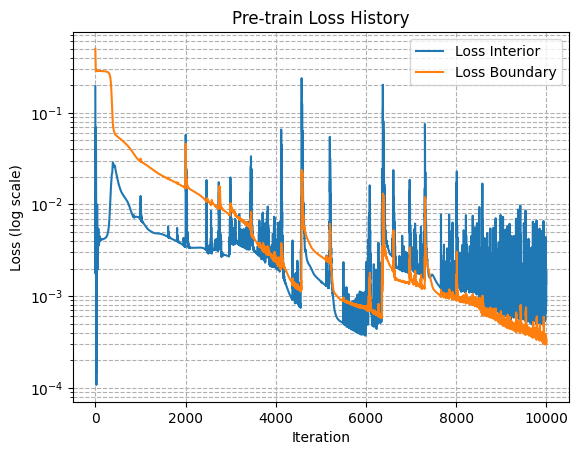


Plotting after training segment 1/3 (t = [0.0000, 0.6667])


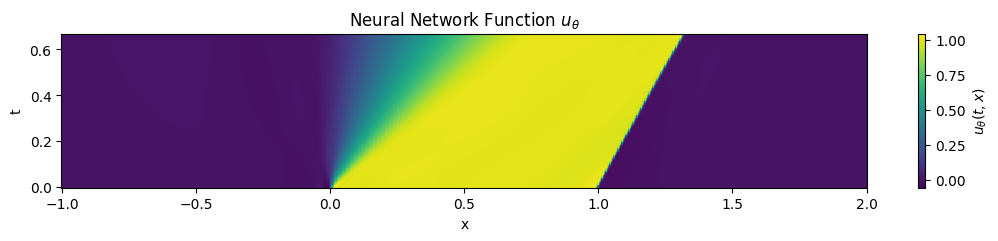


Plotting before training segment 2/3 (t = [0.6667, 1.3333])


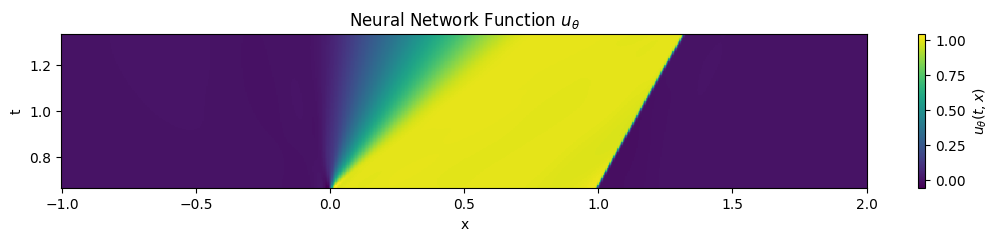


Pre-training segment 2/3 (t = [0.6667, 1.3333])

Starting Pre-Train Stage
Iteration 0, lambda_ic: 1.292760968208313, lambda_bc: 105.68380737304688, lambda_r: 1.0343295335769653.
Pre-train Iteration 0, Loss_int: 0.00259938, Loss_ibc: 0.17592604
Pre-train Iteration 200, Loss_int: 0.00959175, Loss_ibc: 0.07873465
Pre-train Iteration 400, Loss_int: 0.01027192, Loss_ibc: 0.05802000
Pre-train Iteration 600, Loss_int: 0.00668645, Loss_ibc: 0.04566217
Pre-train Iteration 800, Loss_int: 0.00510428, Loss_ibc: 0.03371219
Iteration 1000, lambda_ic: 1.3860570192337036, lambda_bc: 415.7091369628906, lambda_r: 1.112584114074707.
Pre-train Iteration 1000, Loss_int: 0.00413622, Loss_ibc: 0.02684812
Pre-train Iteration 1200, Loss_int: 0.00333906, Loss_ibc: 0.02224876
Pre-train Iteration 1400, Loss_int: 0.00324662, Loss_ibc: 0.01908359
Pre-train Iteration 1600, Loss_int: 0.00321434, Loss_ibc: 0.01733590
Pre-train Iteration 1800, Loss_int: 0.00321360, Loss_ibc: 0.01664406
Iteration 2000, lambda_ic: 1.471

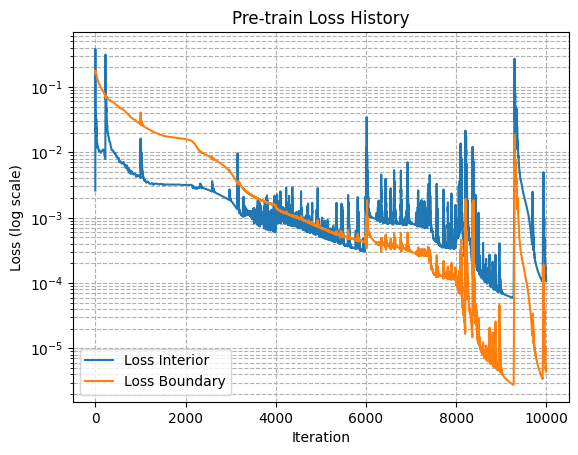


Plotting after training segment 2/3 (t = [0.6667, 1.3333])


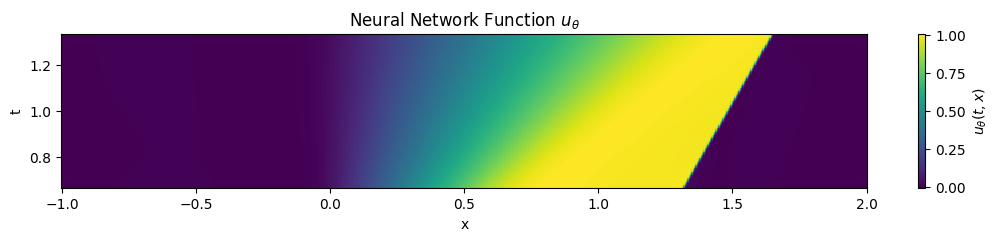


Plotting before training segment 3/3 (t = [1.3333, 2.0000])


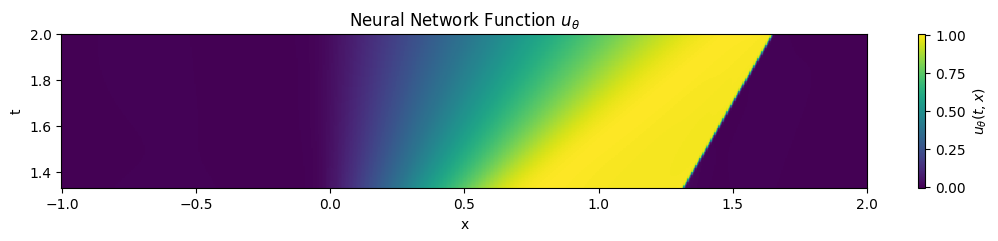


Pre-training segment 3/3 (t = [1.3333, 2.0000])

Starting Pre-Train Stage
Iteration 0, lambda_ic: 1.0044194459915161, lambda_bc: 137.74124145507812, lambda_r: 3.304250717163086.
Pre-train Iteration 0, Loss_int: 0.00010823, Loss_ibc: 0.14355409
Pre-train Iteration 200, Loss_int: 0.00083159, Loss_ibc: 0.09034730
Pre-train Iteration 400, Loss_int: 0.00105534, Loss_ibc: 0.07526924
Pre-train Iteration 600, Loss_int: 0.00078522, Loss_ibc: 0.02206806
Pre-train Iteration 800, Loss_int: 0.00040711, Loss_ibc: 0.01038160
Iteration 1000, lambda_ic: 1.029422640800476, lambda_bc: 242.96304321289062, lambda_r: 3.468878746032715.
Pre-train Iteration 1000, Loss_int: 0.00030512, Loss_ibc: 0.00761988
Pre-train Iteration 1200, Loss_int: 0.00019130, Loss_ibc: 0.00515420
Pre-train Iteration 1400, Loss_int: 0.00015367, Loss_ibc: 0.00363654
Pre-train Iteration 1600, Loss_int: 0.00012687, Loss_ibc: 0.00266931
Pre-train Iteration 1800, Loss_int: 0.00013823, Loss_ibc: 0.00222889
Iteration 2000, lambda_ic: 1.056

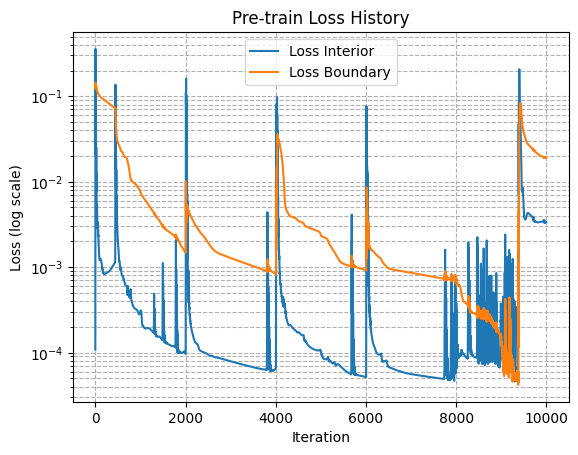


Plotting after training segment 3/3 (t = [1.3333, 2.0000])


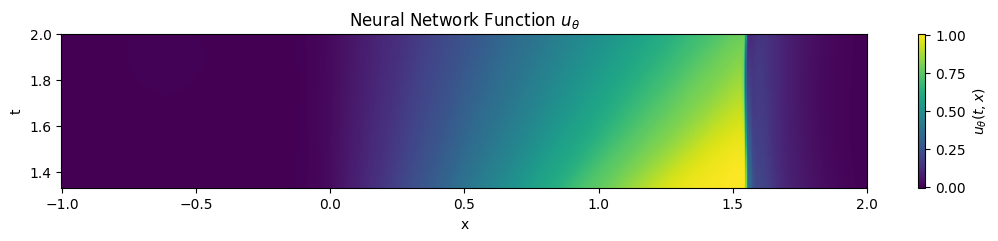

In [8]:
seq_trainer.train_sequential(train_num_iterations=0, pre_train_num_iterations=10000)

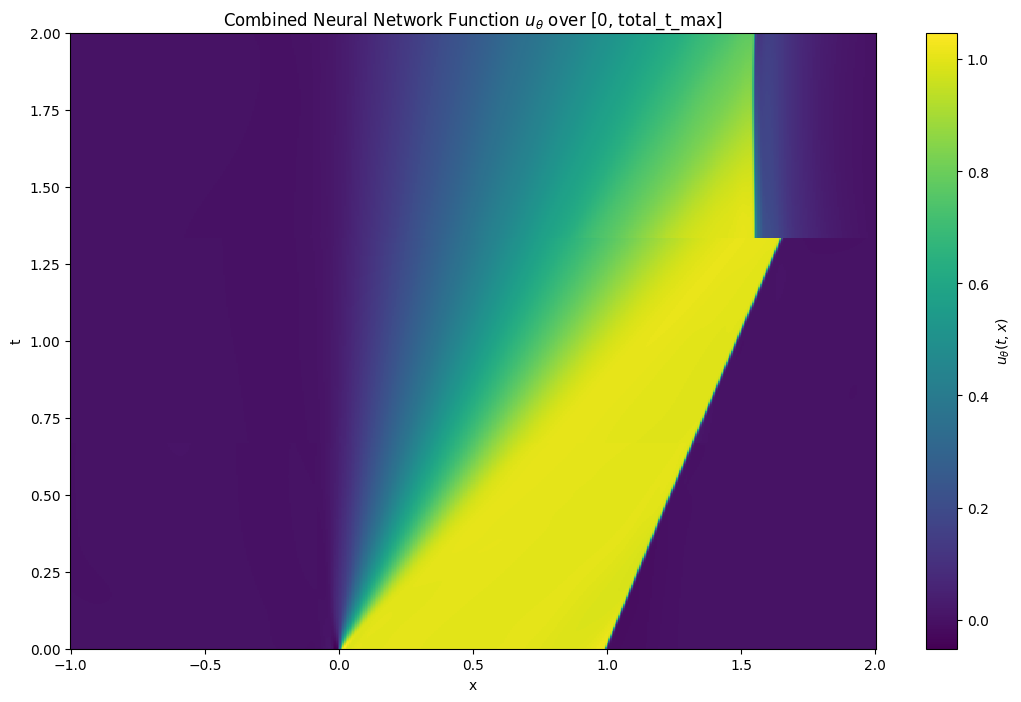

In [10]:

plot_combined_u_theta(seq_trainer)